# 01 · Audit the official local radar sample

**Status:** AI-assisted data exploration; model inference and training are not performed.

**Source:** `DSIP-FBK/IT4LIA-FBK-Seminar`, revision `676ffe7f941511bbdd955cfe9ec8bf51d05aad0e`, `module2-irene-nowcasting/examples/sample_data.nc`.

This original companion notebook checks shape, time cadence, coordinate order, missingness and unit metadata. It processes one frame at a time for statistics. The raw sample is not redistributed.

**Important:** the file declares `kg m-2 s-1`, while course/model documentation describes rain rate in `mm/h`. We keep numeric values unchanged and leave physical units unresolved. Do not multiply by 3600 or infer calibrated rain amounts without checking provenance.

In [1]:
import os
import sys
import json
import hashlib
import subprocess
import importlib.metadata as metadata
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
SOURCE = Path(os.environ.get('IT4LIA_REPO', str(ROOT.parent / 'IT4LIA-FBK-Seminar'))).expanduser().resolve()
SAMPLE = SOURCE / 'module2-irene-nowcasting/examples/sample_data.nc'
assert SAMPLE.is_file(), 'Clone the official seminar repository beside this project, or set IT4LIA_REPO.'
for folder in ('reports', 'figures'):
    (ROOT / folder).mkdir(exist_ok=True)

expected_commit = '676ffe7f941511bbdd955cfe9ec8bf51d05aad0e'
source_commit = subprocess.check_output(['git', '-C', str(SOURCE), 'rev-parse', 'HEAD'], text=True).strip()
assert source_commit == expected_commit, 'Select the documented upstream revision before reproducing this audit.'
print('Python:', sys.version.split()[0])
print('Upstream revision:', source_commit)
print('File size (MB):', round(SAMPLE.stat().st_size / 1e6, 2))

Python: 3.12.14
Upstream revision: 676ffe7f941511bbdd955cfe9ec8bf51d05aad0e
File size (MB): 11.23


## Inspect dimensions and metadata

Coordinates and attributes are part of the scientific input. The sample refers to a `crs` grid mapping but does not include that scalar variable. We can inspect projected x/y coordinates but will not invent a geographic projection for this file.

In [2]:
ds = xr.open_dataset(SAMPLE, engine='h5netcdf')
rr = ds['RR']
assert rr.dims == ('time', 'y', 'x'), rr.dims
assert rr.dtype == np.float32, rr.dtype
assert ds.sizes['time'] >= 18, 'Need six input frames and twelve later frames for a future evaluation.'
times = pd.DatetimeIndex(ds.time.values)
assert times.is_monotonic_increasing and times.is_unique
cadence = np.diff(times.values) / np.timedelta64(1, 'm')
assert np.all(cadence == 5), 'This sample should have a regular five-minute cadence.'
assert np.all(np.diff(ds.x.values) > 0)
assert np.all(np.diff(ds.y.values) < 0)
assert np.allclose(np.diff(ds.x.values), 1000)
assert np.allclose(np.diff(ds.y.values), -1000)
print(ds)
print('RR attributes:', rr.attrs)
print('In-memory RR size (MB):', rr.nbytes / 1e6)
print('Grid mapping variable present:', rr.attrs.get('grid_mapping') in ds)
print('Unit status: unresolved; original values retained.')

<xarray.Dataset> Size: 363MB
Dimensions:  (time: 54, y: 1400, x: 1200)
Coordinates:
  * time     (time) datetime64[ns] 432B 2025-08-28T21:55:00 ... 2025-08-29T02...
  * y        (y) float64 11kB 6.495e+05 6.485e+05 ... -7.485e+05 -7.495e+05
  * x        (x) float64 10kB -5.995e+05 -5.985e+05 ... 5.985e+05 5.995e+05
Data variables:
    RR       (time, y, x) float32 363MB ...
RR attributes: {'grid_mapping': 'crs', 'long_name': 'Total precipitation rate', 'standard_name': 'tprate', 'units': 'kg m-2 s-1'}
In-memory RR size (MB): 362.88
Grid mapping variable present: False
Unit status: unresolved; original values retained.


## Keep missing observations separate from zero values

We calculate positive-value fraction **among finite pixels**, not among the full rectangle. Positive raw values are a numerical description here, not a verified physical threshold. A NaN is an unavailable observation; replacing it with zero would change the interpretation of coverage and error metrics.

In [3]:
records = []
for index in range(rr.sizes['time']):
    frame = rr.isel(time=index).values
    finite = np.isfinite(frame)
    values = frame[finite]
    assert values.size > 0
    assert np.all(values >= 0), 'Investigate negative/sentinel values before proceeding.'
    records.append({
        'time': str(times[index]),
        'finite_pixel_fraction': float(finite.mean()),
        'zero_fraction_among_finite': float((values == 0).mean()),
        'positive_fraction_among_finite': float((values > 0).mean()),
        'mean_raw_among_finite': float(values.mean()),
        'p99_raw': float(np.percentile(values, 99)),
        'max_raw': float(values.max()),
    })
stats = pd.DataFrame(records)
stats.to_csv(ROOT / 'reports/frame_statistics.csv', index=False)
display(stats.head())
summary = {
    'source_repository': 'https://github.com/DSIP-FBK/IT4LIA-FBK-Seminar',
    'upstream_commit': source_commit,
    'sample_relative_path': 'module2-irene-nowcasting/examples/sample_data.nc',
    'sample_sha256': hashlib.sha256(SAMPLE.read_bytes()).hexdigest(),
    'file_bytes': SAMPLE.stat().st_size,
    'variable': 'RR',
    'shape': list(rr.shape),
    'dtype': str(rr.dtype),
    'uncompressed_variable_bytes': rr.nbytes,
    'first_timestamp': str(times[0]),
    'last_timestamp': str(times[-1]),
    'timezone': 'not encoded in sample timestamps',
    'cadence_minutes': sorted(set(float(x) for x in cadence)),
    'declared_units': rr.attrs.get('units'),
    'interpretation': 'unresolved discrepancy with course mm/h documentation; no conversion applied',
    'grid_mapping_variable_present': rr.attrs.get('grid_mapping') in ds,
    'valid_fraction_min': float(stats.finite_pixel_fraction.min()),
    'valid_fraction_max': float(stats.finite_pixel_fraction.max()),
    'model_inference_performed': False,
    'versions': {name: metadata.version(name) for name in ('numpy','pandas','xarray','matplotlib','h5netcdf','h5py')},
}
(ROOT / 'reports/sample_audit.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(json.dumps(summary, indent=2))

{
  "source_repository": "https://github.com/DSIP-FBK/IT4LIA-FBK-Seminar",
  "upstream_commit": "676ffe7f941511bbdd955cfe9ec8bf51d05aad0e",
  "sample_relative_path": "module2-irene-nowcasting/examples/sample_data.nc",
  "sample_sha256": "1a94b2f0c576f8e80cac470b1994bf8faed3eae11fb6fee6feba21e1a52dc0e7",
  "file_bytes": 11232217,
  "variable": "RR",
  "shape": [
    54,
    1400,
    1200
  ],
  "dtype": "float32",
  "uncompressed_variable_bytes": 362880000,
  "first_timestamp": "2025-08-28 21:55:00",
  "last_timestamp": "2025-08-29 02:20:00",
  "timezone": "not encoded in sample timestamps",
  "cadence_minutes": [
    5.0
  ],
  "declared_units": "kg m-2 s-1",
  "interpretation": "unresolved discrepancy with course mm/h documentation; no conversion applied",
  "grid_mapping_variable_present": false,
  "valid_fraction_min": 0.4412595238095238,
  "valid_fraction_max": 0.4814327380952381,
  "model_inference_performed": false,
  "versions": {
    "numpy": "2.3.5",
    "pandas": "2.2.3",
  

,time,finite_pixel_fraction,zero_fraction_among_finite,positive_fraction_among_finite,mean_raw_among_finite,p99_raw,max_raw
0,2025-08-28 21:55:00,0.480952,0.842698,0.157302,0.611951,12.179688,61.56250
1,2025-08-28 22:00:00,0.480955,0.845006,0.154994,0.584106,11.703125,69.50000
2,2025-08-28 22:05:00,0.480971,0.844455,0.155545,0.599885,12.200684,60.40625
3,2025-08-28 22:10:00,0.481413,0.837997,0.162003,0.644930,12.548828,64.31250
4,2025-08-28 22:15:00,0.481261,0.837340,0.162660,0.624245,12.179688,80.56250


## Visualize the raw fields

The y coordinate descends, so `origin="upper"` is intentional. All panels share one color scale, capped at the largest per-frame 99th percentile. Higher values are saturated rather than rescaled independently. The axes show projected-coordinate offsets in kilometres, not latitude/longitude.

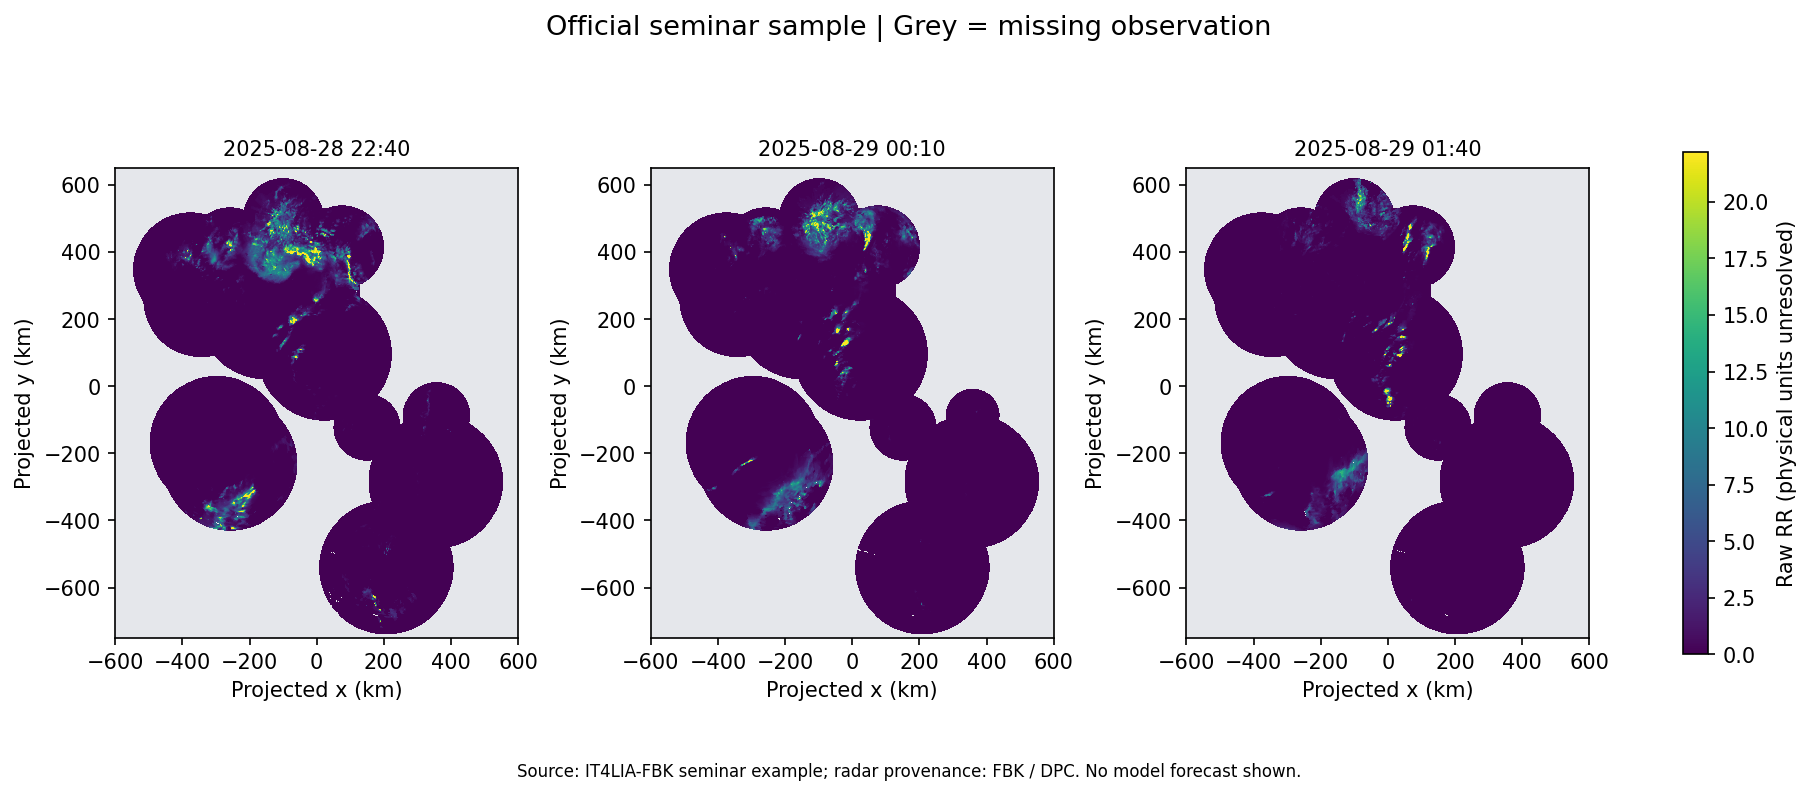

In [4]:
indices = [9, 27, 45]
extent = [(float(ds.x[0])-500)/1000, (float(ds.x[-1])+500)/1000,
          (float(ds.y[-1])-500)/1000, (float(ds.y[0])+500)/1000]
vmax = max(row['p99_raw'] for row in records)
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('#e5e7eb')
fig, axes = plt.subplots(1, 3, figsize=(12, 5), constrained_layout=True)
for ax, index in zip(axes, indices):
    im = ax.imshow(rr.isel(time=index).values, origin='upper', extent=extent,
                   cmap=cmap, vmin=0, vmax=vmax, interpolation='nearest')
    ax.set_title(times[index].strftime('%Y-%m-%d %H:%M'), fontsize=10)
    ax.set_xlabel('Projected x (km)')
    ax.set_ylabel('Projected y (km)')
fig.colorbar(im, ax=axes, shrink=0.72, label='Raw RR (physical units unresolved)')
fig.suptitle('Official seminar sample | Grey = missing observation', fontsize=13)
fig.text(0.5, -0.025, 'Source: IT4LIA-FBK seminar example; radar provenance: FBK / DPC. No model forecast shown.', ha='center', fontsize=8)
fig.savefig(ROOT / 'figures/sample_frames.png', dpi=150, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(ROOT / 'figures/sample_frames.png')))

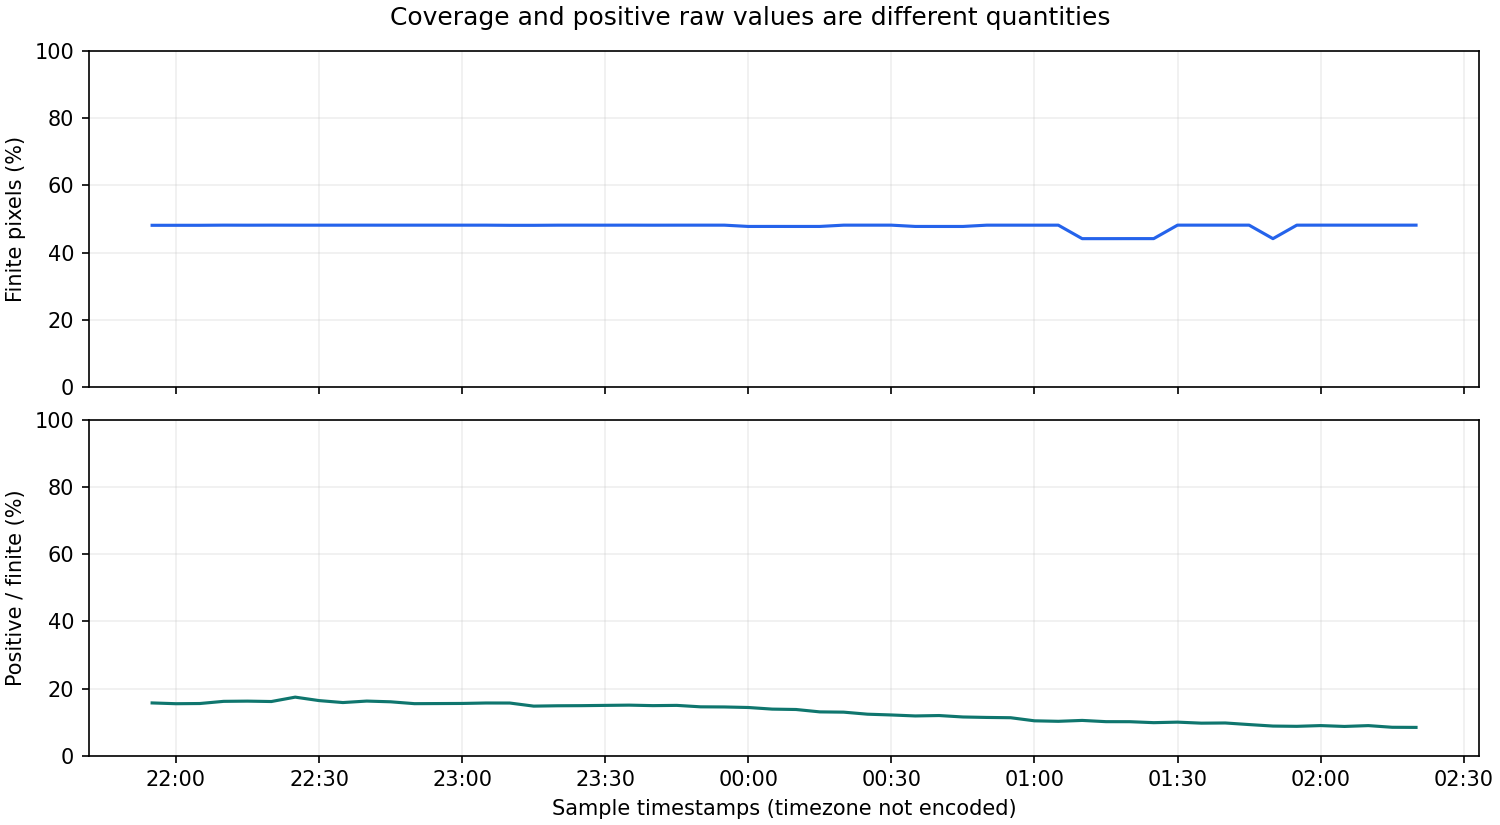

In [5]:
import matplotlib.dates as mdates
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, constrained_layout=True)
axes[0].plot(times, stats.finite_pixel_fraction * 100, color='#2563eb')
axes[0].set_ylabel('Finite pixels (%)')
axes[0].set_ylim(0, 100)
axes[1].plot(times, stats.positive_fraction_among_finite * 100, color='#0f766e')
axes[1].set_ylabel('Positive / finite (%)')
axes[1].set_ylim(0, 100)
axes[1].set_xlabel('Sample timestamps (timezone not encoded)')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
for ax in axes:
    ax.grid(alpha=0.2)
fig.suptitle('Coverage and positive raw values are different quantities')
fig.savefig(ROOT / 'figures/coverage_summary.png', dpi=150)
plt.close(fig)
display(Image(filename=str(ROOT / 'figures/coverage_summary.png')))

## Build an exact six-frame input and a strictly later target

A label slice includes both endpoints: `T0 - 30 min` through `T0` can contain seven five-minute frames. Select the last six observed timestamps explicitly, then select twelve later timestamps. This is a shape/time check only, not yet a model experiment.

In [6]:
t0 = times[9]
past = rr.sel(time=slice(None, t0)).isel(time=slice(-6, None))
future = rr.sel(time=slice(t0 + pd.Timedelta(minutes=5), t0 + pd.Timedelta(minutes=60)))
assert past.sizes['time'] == 6
assert future.sizes['time'] == 12
assert past.time.values[-1] < future.time.values[0]
assert np.all(np.diff(past.time.values) == np.timedelta64(5, 'm'))
print('Input timestamps:', past.time.values)
print('Future timestamps:', future.time.values)
print('Shapes:', past.shape, future.shape)
print('No forecast was generated. Resolve units before inference/evaluation.')
ds.close()

Input timestamps: ['2025-08-28T22:15:00.000000000' '2025-08-28T22:20:00.000000000'
 '2025-08-28T22:25:00.000000000' '2025-08-28T22:30:00.000000000'
 '2025-08-28T22:35:00.000000000' '2025-08-28T22:40:00.000000000']
Future timestamps: ['2025-08-28T22:45:00.000000000' '2025-08-28T22:50:00.000000000'
 '2025-08-28T22:55:00.000000000' '2025-08-28T23:00:00.000000000'
 '2025-08-28T23:05:00.000000000' '2025-08-28T23:10:00.000000000'
 '2025-08-28T23:15:00.000000000' '2025-08-28T23:20:00.000000000'
 '2025-08-28T23:25:00.000000000' '2025-08-28T23:30:00.000000000'
 '2025-08-28T23:35:00.000000000' '2025-08-28T23:40:00.000000000']
Shapes: (6, 1400, 1200) (12, 1400, 1200)
No forecast was generated. Resolve units before inference/evaluation.


## Interpretation and next experiment

1. Explain why an approximately 11 MB file can represent approximately 363 MB of raw values.
2. Explain why coverage and positive-value fraction use different denominators.
3. Resolve the sample's unit metadata against a matching cloud observation or the export process.
4. Then run IRENE on a small region and compare it with persistence, evaluating only valid observed pixels.
5. Report single-event results as a case study; evaluate multiple independent events before generalizing.

Do not describe this first audit as model training or performance improvement. Record your own rerun and explanations in `docs/experiment-log.md`.